# Liver demo: ECM composition, graphs and GNN explanation

**Estimated runtime: 8–15 minutes on an RTX 4070 SUPER with eight CPU
threads**, excluding installation and the first download.
**Measured runtime: 7 min 37 s** with an RTX 4070 SUPER and eight CPU threads, using cached downloads.

Analyse the public 24-ROI, eight-mouse, six-marker cohort with the paper's
selected settings. **Seed 0; one shared CNN fit; six ECM clusters.** Then
describe composition and spatial organisation, hold out one infected mouse
for GraphSAGE prediction, and explain one of its ROIs with integrated gradients.

This fresh-fit demonstration performs no parameter search. The paper's
saved outputs and full eight-fold/five-seed analysis are in the
reproducibility repository. Keep `liver_demo_helpers.py` beside this notebook.

## Setup

In Colab, keep runtime version **Latest** and select a GPU under
**Runtime > Change runtime type**. Run setup, restart when requested,
then run all cells.
Locally, install `liver_demo_requirements.txt` in
Python 3.11/3.12/3.13 and keep the helper beside the notebook.


In [1]:
import importlib.util
try:
    in_colab = importlib.util.find_spec("google.colab") is not None
except ModuleNotFoundError:
    in_colab = False

if in_colab:
    from pathlib import Path
    from urllib.request import urlretrieve
    if not Path("colab_setup.py").exists():
        urlretrieve("https://raw.githubusercontent.com/moeghaf/mantpy_reproducibility/main/notebooks/demos/colab_setup.py", "colab_setup.py")
    from colab_setup import prepare_colab
    prepare_colab("liver")


In [2]:
from pathlib import Path
import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import anndata as ad
import mantpy as mt
import torch
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from threadpoolctl import threadpool_limits
from liver_demo_helpers import (
    seed_everything, fit_liver_cnn, fit_liver_gnn,
    infected_probability, liver_integrated_gradients, show_patch_map,
)

SEED = 0
PATCH_SIZE = 10
K = 6
HELD_OUT_MOUSE = "mouse_03"
DISPLAY_ROI = "roi_009"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
seed_everything(SEED)
torch.set_num_threads(8)
threadpool_limits(limits=8)
result_dir = Path("demo_results")
result_dir.mkdir(exist_ok=True)
stages = {}
started = time.perf_counter()
print(f"Seed {SEED}; CNN: {DEVICE}; GraphSAGE: CPU")


<python-environment>/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Seed 0; CNN: cuda; GraphSAGE: CPU


## 1. Load the cohort and visualise one ROI

The same cohort defines the pixel transform and the shared CNN. The
displayed ROI is from the mouse that will be held out from supervised
training. Infection and genotype labels are not used by the CNN or K-means.


In [3]:
bundle = mt.datasets.schistosoma_ecm(cache_dir=Path("data"))
markers = list(bundle.ecm_names)
meta = bundle.sample_meta.sort_index().copy()
assert len(meta) == 24 and meta["mouse_id"].nunique() == 8 and len(markers) == 6
assert meta.loc[DISPLAY_ROI, "mouse_id"] == HELD_OUT_MOUSE
display(meta.groupby(["group", "mouse_id"], observed=True).size().rename("ROIs").to_frame())
print("Markers:", ", ".join(markers))


Loaded 24 ROIs


,sample_id,mouse_id,condition,genotype,group
sample_id,,,,,
roi_001,roi_001,mouse_01,Infected,KO,Infected_KO
roi_002,roi_002,mouse_01,Infected,KO,Infected_KO
roi_003,roi_003,mouse_01,Infected,KO,Infected_KO
roi_004,roi_004,mouse_01,Infected,KO,Infected_KO
roi_005,roi_005,mouse_02,Infected,KO,Infected_KO


ROIs
group       mouse_id      
Naive_KO    mouse_05     2
            mouse_06     2
Naive_WT    mouse_07     2
            mouse_08     2
Infected_KO mouse_01     4
            mouse_02     4
Infected_WT mouse_03     4
            mouse_04     4

Markers: Fibronectin, Pan-laminin, CollagenIV, VersicanV0V1, CollagenI, HeparanSulfate


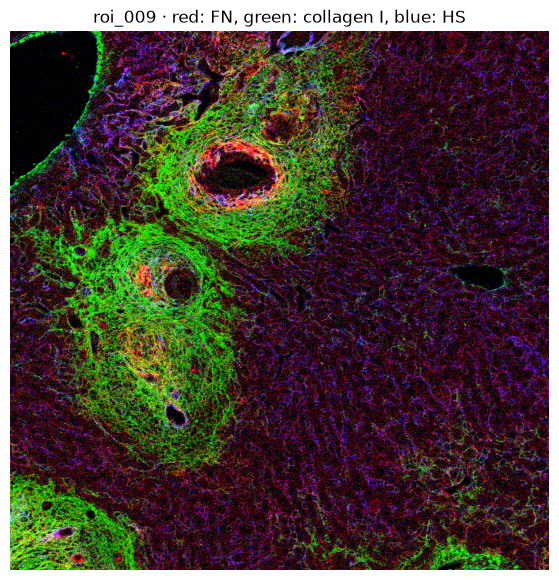

In [4]:
# A three-marker view of the six-channel image; scaling here is for display only.
raw = np.asarray(bundle.images[DISPLAY_ROI], dtype=np.float32)
rgb = np.moveaxis(np.arcsinh(raw[[0, 4, 5]]), 0, -1)
rgb /= np.maximum(np.percentile(rgb, 99.5, axis=(0, 1)), 1e-8)
plt.figure(figsize=(7, 7))
plt.imshow(np.clip(rgb, 0, 1))
plt.title(f"{DISPLAY_ROI} · red: FN, green: collagen I, blue: HS")
plt.axis("off")
plt.show()


## 2. Shared preprocessing and ECM signal patches

Apply arcsinh with cofactor 1, divide each marker by its pooled 99.5th
percentile across the 24 ROIs and clip to [0, 1]. Extract 10 × 10-pixel
patches with six means and six population standard deviations. Two-component
K-means of the pooled standardised summaries identifies the dim background.


In [5]:
stage_start = time.perf_counter()
cohort = mt.pp.ecm_patches_from_images(
    {roi: bundle.images[roi] for roi in meta.index}, bundle.panel,
    normalize="pooled_arcsinh_percentile", cofactor=1.0, percentile=99.5,
    patch_size=PATCH_SIZE, features=["mean", "std"],
    ecm_K=None, background_quantile=0.0,
)
background_fit = mt.pp.cluster_ecm_patches(
    cohort, n_clusters=2, random_state=SEED, n_init=10,
)
mt.pp.remove_background_patches(cohort, background_fit)
display(mt.pp.ecm_patch_summary(cohort, cluster_key="ecm_cluster"))
stages["preprocessing_seconds"] = time.perf_counter() - stage_start


ECM patch cohort
  samples       24
  patches       240,000
  features      12 per patch
  background    132,268
  ECM 0        107,732

## 3. Train one selected CNN on the retained patches

Two stride-2 convolution blocks (widths 32 and 64), BatchNorm and GELU;
maximum pooling to 2 × 2 and a 96-dimensional readout. Contrastive projection
96 → 96 → 64, temperature 0.1, default augmentation, 200 epochs and batch
size 1,024. AdamW uses learning rate 0.0003 and weight decay 0.0001.

The summaries and CNN blocks use the same normalisation bounds and patch
coordinates. Each retained patch is used once in this shared CNN input.


In [6]:
bounds = np.asarray(next(iter(cohort.values())).uns["ecm_pixel_normalization"]["bounds"])
tables, window_blocks = [], []
for roi in meta.index:
    table = cohort[roi].uns["ecm_patches"].copy()
    table["roi"] = roi
    for column in ["mouse_id", "condition", "genotype", "group"]:
        table[column] = str(meta.loc[roi, column])
    table["signal"] = table["ecm_cluster"] >= 0
    gx = ((table["x"].to_numpy() - PATCH_SIZE / 2) // PATCH_SIZE).astype(int)
    gy = ((table["y"].to_numpy() - PATCH_SIZE / 2) // PATCH_SIZE).astype(int)
    image = np.asarray(bundle.images[roi], dtype=np.float32)
    image = np.clip(np.arcsinh(image) / bounds[:, None, None], 0, 1)
    channels, height, width = image.shape
    blocks = image.reshape(channels, height // 10, 10, width // 10, 10).transpose(1, 3, 0, 2, 4)
    signal = table["signal"].to_numpy()
    window_blocks.append(blocks[gy[signal], gx[signal]])
    tables.append(table)
nodes = pd.concat(tables, ignore_index=True)
windows = np.concatenate(window_blocks).astype(np.float32)
assert len(nodes) == 240000 and len(windows) == int(nodes["signal"].sum())
print(f"{len(nodes):,} total patches; {len(windows):,} signal blocks {windows.shape[1:]}")
del window_blocks, blocks, image


240,000 total patches; 107,732 signal blocks (6, 10, 10)


Shared liver CNN:   0%|          | 0/200 [00:00<?, ?it/s]<python-environment>/site-packages/torch/autograd/graph.py:979: UserWarning: adaptive_max_pool2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\Context.cpp:190.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass
Shared liver CNN: 100%|██████████| 200/200 [04:48<00:00,  1.44s/it, loss=0.280]


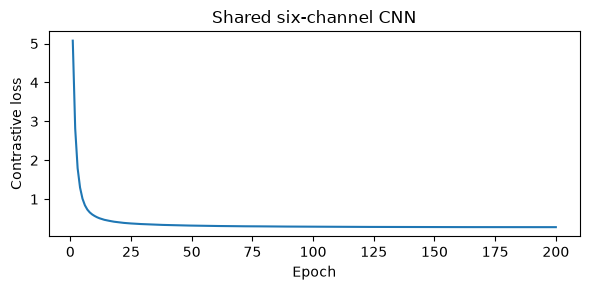

In [7]:
stage_start = time.perf_counter()
cnn, raw_embedding, cnn_loss = fit_liver_cnn(
    windows, seed=SEED, latent_dim=96, projection_dim=64, temperature=0.1,
    epochs=200, batch_size=1024, lr=3e-4, weight_decay=1e-4, device=DEVICE,
)
stages["cnn_seconds"] = time.perf_counter() - stage_start
np.save(result_dir / "cnn_raw_embedding.npy", raw_embedding)
np.save(result_dir / "cnn_loss.npy", cnn_loss)
torch.save(cnn.cpu().state_dict(), result_dir / "cnn_seed0.pt")
del windows
plt.figure(figsize=(6, 3))
plt.plot(np.arange(1, 201), cnn_loss)
plt.xlabel("Epoch")
plt.ylabel("Contrastive loss")
plt.title("Shared six-channel CNN")
plt.tight_layout()
plt.show()


## 4. Six ECM clusters

Standardise the raw CNN embedding **once**, then K-means at the fixed K=6.
This follows the selected clustering source; its `cnn_standardize=False`
flag controls the exported encoder array, not the downstream K-means input.
Renumber clusters by decreasing size for a stable display convention.


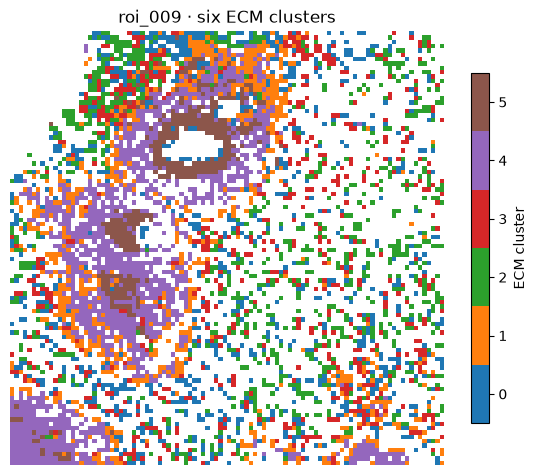

In [8]:
embedding = StandardScaler().fit_transform(raw_embedding).astype(np.float32)
raw_labels = KMeans(n_clusters=K, n_init=10, random_state=SEED).fit_predict(embedding)
order = sorted(range(K), key=lambda value: (-int((raw_labels == value).sum()), value))
relabel = {value: index for index, value in enumerate(order)}
labels = np.asarray([relabel[value] for value in raw_labels], dtype=int)
nodes["ecm_cluster"] = -1
nodes.loc[nodes["signal"], "ecm_cluster"] = labels
for roi in meta.index:
    cohort[roi].uns["ecm_patches"]["ecm_cluster"] = nodes.loc[nodes["roi"] == roi, "ecm_cluster"].to_numpy()
assert len(np.unique(labels)) == K and np.isfinite(embedding).all()
np.save(result_dir / "cnn_embedding_standardised.npy", embedding)
np.save(result_dir / "ecm_labels_seed0.npy", labels)
nodes.to_csv(result_dir / "patch_table.csv.gz", index=False)
show_patch_map(nodes[nodes["roi"] == DISPLAY_ROI], f"{DISPLAY_ROI} · six ECM clusters")


## 5. Marker profiles and mouse-level composition

Marker profiles average each marker's patch mean within a cluster, then
z-score across the six clusters. Mouse fractions pool its ROIs; group
compositions average the two mice with equal weight.


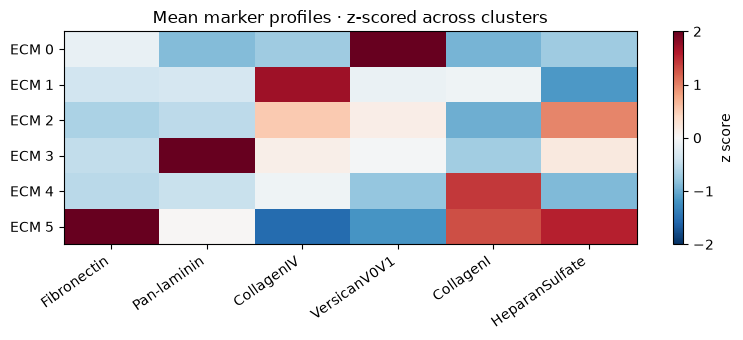

In [9]:
signal_nodes = nodes.loc[nodes["signal"]].copy()
mean_columns = [f"feat_{i}" for i in range(6)]
profiles = signal_nodes.astype({c: float for c in mean_columns}).groupby("ecm_cluster")[mean_columns].mean()
profiles.columns = markers
profile_z = (profiles - profiles.mean()) / profiles.std(ddof=0).replace(0, 1)
fig, ax = plt.subplots(figsize=(8, 3.5))
image = ax.imshow(profile_z, cmap="RdBu_r", vmin=-2, vmax=2, aspect="auto")
ax.set_xticks(range(6), markers, rotation=35, ha="right")
ax.set_yticks(range(K), [f"ECM {value}" for value in range(K)])
ax.set_title("Mean marker profiles · z-scored across clusters")
fig.colorbar(image, ax=ax, label="z score")
plt.tight_layout()
plt.show()


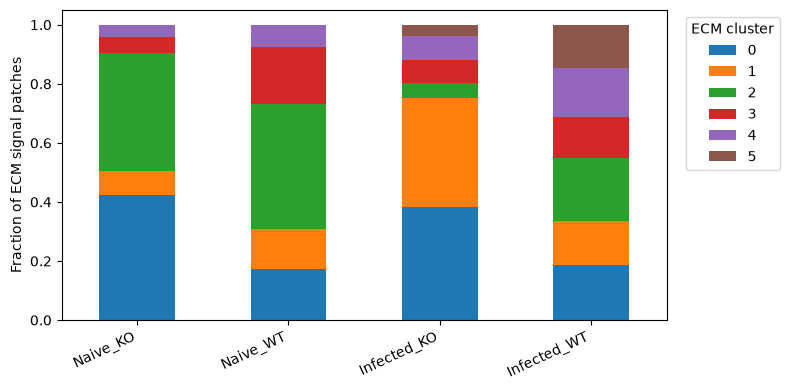

ecm_cluster,0,1,2,3,4,5
mouse_id,,,,,,
mouse_01,0.2470,0.5344,0.0373,0.0680,0.0839,0.0294
mouse_02,0.5204,0.2038,0.0658,0.0862,0.0752,0.0486
mouse_03,0.1664,0.1344,0.2524,0.1460,0.2126,0.0882
mouse_04,0.2049,0.1659,0.1767,0.1319,0.1144,0.2062
mouse_05,0.5002,0.0486,0.3445,0.0605,0.0460,0.0002
mouse_06,0.3483,0.1152,0.4536,0.0458,0.0372,0.0000
mouse_07,0.1672,0.1352,0.4000,0.2006,0.0970,0.0000
mouse_08,0.1789,0.1325,0.4464,0.1869,0.0553,0.0000


In [10]:
counts = signal_nodes.groupby(["mouse_id", "ecm_cluster"]).size().unstack(fill_value=0).reindex(columns=range(K), fill_value=0)
mouse_fractions = counts.div(counts.sum(axis=1), axis=0)
mouse_group = meta.groupby("mouse_id", observed=True)["group"].first()
group_fractions = mouse_fractions.assign(group=mouse_group).groupby("group", observed=True).mean()
group_fractions = group_fractions.reindex(bundle.group_order)
ax = group_fractions.plot.bar(stacked=True, figsize=(8, 4), color=list(plt.get_cmap("tab10").colors[:K]))
ax.set_ylabel("Fraction of ECM signal patches")
ax.set_xlabel("")
ax.legend(title="ECM cluster", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()
display(mouse_fractions.round(4))


## 6. Identify infection-associated ECM after clustering

Among clusters occupying at least 1% of patches in every infected mouse,
choose the largest infected-to-naive mean fraction ratio (pseudocount 0.001).
If no cluster meets the presence rule, the recorded fallback is the largest
infected-minus-naive difference. Fresh cluster numbers are arbitrary.


In [11]:
infected = mouse_fractions.loc[mouse_group.astype(str).str.startswith("Infected")]
naive = mouse_fractions.loc[mouse_group.astype(str).str.startswith("Naive")]
ratio = np.log2((infected.mean() + 0.001) / (naive.mean() + 0.001))
present = (infected >= 0.01).all()
eligible = ratio[present].sort_values(ascending=False, kind="mergesort")
remodeling_cluster = int(eligible.index[0]) if len(eligible) else int((infected.mean() - naive.mean()).idxmax())
remodeling_summary = pd.DataFrame({
    "mean_infected_fraction": infected.mean(), "mean_naive_fraction": naive.mean(),
    "log2_ratio": ratio, "present_in_every_infected_mouse": present,
})
print(f"Infection-associated ECM cluster: {remodeling_cluster}")
display(remodeling_summary.round(4))


Infection-associated ECM cluster: 5


,mean_infected_fraction,mean_naive_fraction,log2_ratio,present_in_every_infected_mouse
ecm_cluster,,,,
0,0.2847,0.2986,-0.0688,True
1,0.2596,0.1079,1.2594,True
2,0.1330,0.4111,-1.6204,True
3,0.1080,0.1234,-0.1909,True
4,0.1215,0.0589,1.0334,True
5,0.0931,0.0001,6.4800,True


## 7. Delaunay graphs and cluster co-occurrence

Triangulate **all** patch centres in each ROI; background remains labelled
−1. Co-occurrence ignores background edges and pools counts within each
mouse before calculating log2(observed/expected). The genotype contrast
averages mice equally.


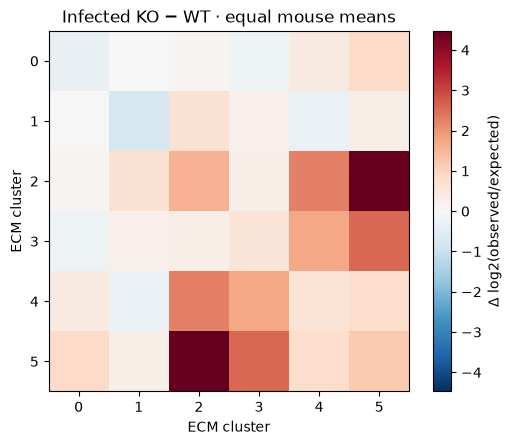

In [12]:
stage_start = time.perf_counter()
for roi in meta.index:
    mt.gr.build_ecm_graph(cohort[roi], edge_method="delaunay", edge_weight="uniform")
stages["graph_seconds"] = time.perf_counter() - stage_start
cooccurrence = {}
for mouse in infected.index:
    rois = meta.index[meta["mouse_id"] == mouse]
    cooccurrence[mouse] = mt.tl.cluster_cooccurrence(
        [cohort[roi] for roi in rois], n_clusters=K, eps=1e-9,
    )
    absent = mouse_fractions.loc[mouse].to_numpy() == 0
    cooccurrence[mouse][absent, :] = np.nan
    cooccurrence[mouse][:, absent] = np.nan
ko = [mouse for mouse in infected.index if str(mouse_group[mouse]) == "Infected_KO"]
wt = [mouse for mouse in infected.index if str(mouse_group[mouse]) == "Infected_WT"]
contrast = np.mean([cooccurrence[mouse] for mouse in ko], axis=0) - np.mean([cooccurrence[mouse] for mouse in wt], axis=0)
fig, ax = plt.subplots(figsize=(5.5, 4.5))
limit = max(1, float(np.nanmax(np.abs(contrast))))
image = ax.imshow(contrast, cmap="RdBu_r", vmin=-limit, vmax=limit)
ax.set_xticks(range(K), range(K))
ax.set_yticks(range(K), range(K))
ax.set(xlabel="ECM cluster", ylabel="ECM cluster", title="Infected KO − WT · equal mouse means")
fig.colorbar(image, ax=ax, label="Δ log2(observed/expected)")
plt.tight_layout()
plt.show()


## 8. Connected regions of remodelled matrix

Join patches of the selected cluster within 40 pixels; retain components
of at least five patches. Report component size and mean node degree.


,,components,median_patches,median_degree
mouse_id,group,,,
mouse_01,Infected_KO,8,11.0,4.10
mouse_02,Infected_KO,10,13.5,7.79
mouse_03,Infected_WT,6,145.5,20.88
mouse_04,Infected_WT,8,66.5,15.19


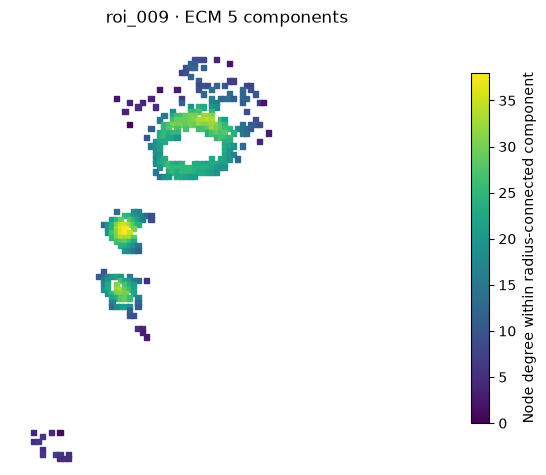

In [13]:
component_rows = []
displayed_components = []
for roi in meta.index:
    components = mt.gr.extract_components_radius_reconnect(
        cohort[roi], target_cluster=remodeling_cluster, radius=40, min_nodes=5,
    )
    kept = [component for component in components if component["kept"]]
    for number, component in enumerate(kept, start=1):
        component_rows.append({
            "roi": roi, "mouse_id": meta.loc[roi, "mouse_id"],
            "group": str(meta.loc[roi, "group"]), "component": number,
            "n_patches": component["n_nodes"],
            "mean_degree": 2 * component["n_edges"] / component["n_nodes"],
        })
    if roi == DISPLAY_ROI:
        displayed_components = kept
subgraph_table = pd.DataFrame(component_rows)
display(subgraph_table.groupby(["mouse_id", "group"]).agg(
    components=("component", "size"),
    median_patches=("n_patches", "median"), median_degree=("mean_degree", "median"),
).round(2))
fig, ax = plt.subplots(figsize=(7, 7))
max_degree = max((degree for component in displayed_components
                  for _, degree in component["subgraph"].degree()), default=1)
max_degree = max(1, max_degree)
for component in displayed_components:
    graph = component["subgraph"]
    degree = np.array([graph.degree(node) for node in sorted(graph.nodes)])
    xy = np.asarray(component["coords"])
    points = ax.scatter(xy[:, 0], xy[:, 1], c=degree, cmap="viridis", marker="s", s=14, vmin=0, vmax=max_degree)
ax.set(xlim=(0, 1000), ylim=(1000, 0), aspect="equal", title=f"{DISPLAY_ROI} · ECM {remodeling_cluster} components")
ax.set_axis_off()
if displayed_components:
    fig.colorbar(points, ax=ax, label="Node degree within radius-connected component", shrink=0.65)
plt.show()


## 9. A mouse-held-out GraphSAGE prediction

The graph uses one-hot ECM cluster identity, with background removed as an
induced subgraph of the full-grid Delaunay graph. Hold out all four ROIs
of mouse_03. Fit input standardisation on the training ROIs only.

GraphSAGE: two mean-aggregation layers, width 64, dropout 0.2, 120 epochs,
Adam learning rate 0.005 and weight decay 0.0001. Prediction uses the
paper's class-weighted loss averaged within each ROI. The shared CNN and
clusters are cohort-defined; this holdout tests the supervised GNN stage.


In [14]:
graph_bundle = mt.nn.build_ohe_cluster_graphs(
    cohort, meta, group_col="condition", group_order=["Naive", "Infected"],
)
train_graphs = [graph for graph in graph_bundle.graphs if meta.loc[graph.roi_id, "mouse_id"] != HELD_OUT_MOUSE]
test_graphs = [graph for graph in graph_bundle.graphs if meta.loc[graph.roi_id, "mouse_id"] == HELD_OUT_MOUSE]
assert len(train_graphs) == 20 and len(test_graphs) == 4
assert sum(graph.num_nodes for graph in graph_bundle.graphs) == len(labels)
print(f"Training: {len(train_graphs)} ROIs; held out: {HELD_OUT_MOUSE}, {len(test_graphs)} ROIs")
stage_start = time.perf_counter()
prediction_fit = fit_liver_gnn(
    train_graphs, loss_objective="roi_mean", seed=SEED, hidden_dim=64,
    n_layers=2, dropout=0.2, epochs=120, lr=0.005, weight_decay=0.0001, device="cpu",
)
stages["prediction_gnn_seconds"] = time.perf_counter() - stage_start
probabilities = pd.DataFrame({
    "roi": [graph.roi_id for graph in test_graphs],
    "P_infected": [infected_probability(prediction_fit, graph) for graph in test_graphs],
})
display(probabilities.round(4))
print(f"{HELD_OUT_MOUSE} mean P(infected): {probabilities['P_infected'].mean():.4f}")


Training: 20 ROIs; held out: mouse_03, 4 ROIs


GraphSAGE · roi_mean: 100%|██████████| 120/120 [00:44<00:00,  2.72it/s]


,roi,P_infected
0,roi_009,0.6123
1,roi_010,0.3497
2,roi_011,0.6980
3,roi_012,0.3826


mouse_03 mean P(infected): 0.5106


## 10. Integrated gradients on one held-out ROI

The paper's explanation uses a second short GNN fit with loss summed over
patches, on the same training graphs and seed. The CNN is reused.

Captum computes 50-step IG towards the mean infected-class logit, from a
zero baseline in training-standardised feature space. Node importance is
the sum of absolute signed attributions across the six cluster features.


GraphSAGE · patch_sum: 100%|██████████| 120/120 [00:44<00:00,  2.72it/s]


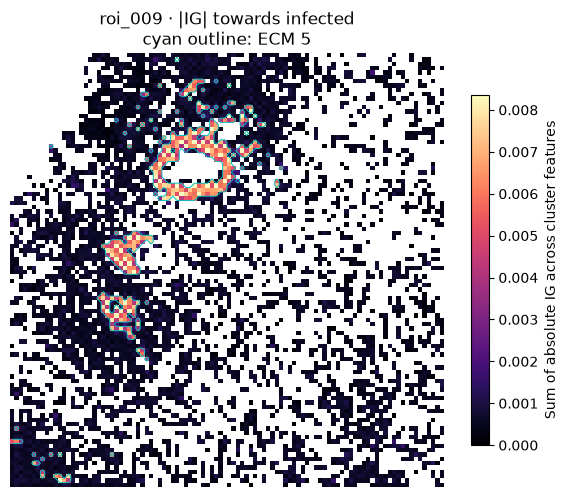

In [15]:
stage_start = time.perf_counter()
explanation_fit = fit_liver_gnn(
    train_graphs, loss_objective="patch_sum", seed=SEED, hidden_dim=64,
    n_layers=2, dropout=0.2, epochs=120, lr=0.005, weight_decay=0.0001, device="cpu",
)
stages["explanation_gnn_seconds"] = time.perf_counter() - stage_start
explain_graph = next(graph for graph in test_graphs if graph.roi_id == DISPLAY_ROI)
stage_start = time.perf_counter()
signed_ig, importance, ig_delta = liver_integrated_gradients(
    explanation_fit, explain_graph, steps=50,
)
stages["integrated_gradients_seconds"] = time.perf_counter() - stage_start
assert signed_ig.shape == tuple(explain_graph.x.shape) and np.isfinite(signed_ig).all()
coords = explain_graph.pos.numpy()
grid = np.full((100, 100), np.nan)
gx = ((coords[:, 0] - 5) // 10).astype(int)
gy = ((coords[:, 1] - 5) // 10).astype(int)
grid[gy, gx] = importance
cluster_grid = np.zeros((100, 100), dtype=bool)
cluster_grid[gy, gx] = explain_graph.cluster.numpy() == remodeling_cluster
fig, ax = plt.subplots(figsize=(7, 7))
image = ax.imshow(grid, cmap="magma", vmin=0, vmax=np.percentile(importance, 99), interpolation="nearest")
if cluster_grid.any() and not cluster_grid.all():
    ax.contour(cluster_grid, levels=[0.5], colors="#00BFC4", linewidths=0.7)
ax.set_title(f"{DISPLAY_ROI} · |IG| towards infected\ncyan outline: ECM {remodeling_cluster}")
ax.set_axis_off()
fig.colorbar(image, ax=ax, label="Sum of absolute IG across cluster features", shrink=0.65)
plt.show()


In [16]:
correlations = []
for cluster in range(K):
    membership = (explain_graph.cluster.numpy() == cluster).astype(float)
    value = float(np.corrcoef(importance, membership)[0, 1]) if 1 < membership.sum() < len(membership) and importance.std() > 0 else np.nan
    correlations.append({"ecm_cluster": cluster, "n_patches": int(membership.sum()), "Pearson_r_abs_IG_membership": value})
ig_correlations = pd.DataFrame(correlations).set_index("ecm_cluster")
display(ig_correlations.round(4))
print(f"IG completeness residual (infected logit): {ig_delta:.3g}")


,n_patches,Pearson_r_abs_IG_membership
ecm_cluster,,
0,832,-0.1543
1,731,-0.1076
2,822,-0.1490
3,657,-0.1177
4,1199,-0.1393
5,375,0.9437


IG completeness residual (infected logit): 0.00259


## 11. Save the fresh-fit results

These outputs contain one training seed and one held-out mouse, not the
paper's ensemble or cohort-level performance estimate.


In [17]:
mouse_fractions.to_csv(result_dir / "mouse_cluster_fractions.csv")
group_fractions.to_csv(result_dir / "group_cluster_fractions.csv")
profiles.to_csv(result_dir / "marker_profiles.csv")
remodeling_summary.to_csv(result_dir / "remodeling_cluster_selection.csv")
pd.DataFrame(contrast).to_csv(result_dir / "cooccurrence_KO_minus_WT.csv")
subgraph_table.to_csv(result_dir / "remodeling_components.csv", index=False)
probabilities.to_csv(result_dir / "held_out_probabilities.csv", index=False)
ig_correlations.to_csv(result_dir / "ig_cluster_correlations.csv")
pd.DataFrame({
    "x": coords[:, 0], "y": coords[:, 1], "ecm_cluster": explain_graph.cluster.numpy(),
    "ig_importance": importance,
}).to_csv(result_dir / "held_out_node_importance.csv", index=False)
np.save(result_dir / "signed_integrated_gradients.npy", signed_ig)
result = ad.AnnData(
    signal_nodes[mean_columns + [f"feat_{i}" for i in range(6, 12)]].to_numpy(dtype=np.float32),
    obs=nodes.loc[nodes["signal"], ["roi", "mouse_id", "condition", "genotype", "group", "ecm_cluster"]].reset_index(drop=True),
)
result.obsm["spatial"] = signal_nodes[["x", "y"]].to_numpy()
result.obsm["X_cnn"] = embedding
result.uns["demo_seed"] = SEED
result.uns["held_out_mouse"] = HELD_OUT_MOUSE
result.uns["remodeling_cluster"] = remodeling_cluster
result.write_h5ad(result_dir / "liver_demo.h5ad")
stages["total_analysis_seconds"] = time.perf_counter() - started
(result_dir / "stage_timings.json").write_text(json.dumps(stages, indent=2))
display(pd.Series(stages, name="Seconds").round(2).to_frame())
print(f"Saved results to {result_dir.resolve()}")


<python-environment>/Lib/functools.py:909: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)


,Seconds
preprocessing_seconds,9.53
cnn_seconds,289.17
graph_seconds,12.04
prediction_gnn_seconds,44.27
explanation_gnn_seconds,44.14
integrated_gradients_seconds,0.75
total_analysis_seconds,436.14


Saved results to demo_results/
